# Digits of pi with the Chudnovsky series (multi-core)

A project that began with a post about the slowly converging Wallis product, which led to Ramanujan's series for 1/pi and the **Chudnovsky formula** (~14.18 digits per term).

## Files in this folder
- **`Digits_of_pi_Chudnovksy_multi_core.ipynb`** - this notebook.
- **`pi_worker.py`** - must sit next to the notebook. Contains `bs_step` (binary splitting), the worker function, the pairwise tree merge, and `calculate_pi_parallel()` with timing checkpoints. It is a separate file because macOS starts worker processes with `spawn`, which cannot see functions defined in a notebook cell.
- **`pi_<N>_digits.txt`** - output written by cell 1 (`3.` then N decimals, wrapped at 80 characters per line).

**Requirements:** `gmpy2`, `numpy`, `matplotlib`. After editing `pi_worker.py`, restart the kernel so workers pick up the change. Save the notebook before running.

## 1. Calculate, save and verify
The next cell:
1. **Asks** how many digits after the decimal point (Enter = 5000).
2. Splits the Chudnovsky terms into chunks, one per CPU core, and computes `(P, Q, T)` for each chunk in parallel with **binary splitting**.
3. **Merges** the 32 results pairwise (tree) and computes `pi = 426880 * sqrt(10005) * Q / T`. Term 0 already contains the `13591409` constant, so the denominator is just `T`.
4. Prints timing and digits/second, then saves the digits to `pi_<N>_digits.txt`.
5. **Verifies** the digits two ways, reporting the position, calculated digit and true digit of any error:
   - against `gmpy2.const_pi()` (all digits, offline);
   - against the **Pi Delivery API** (independent): every digit up to 200,000, or a random sample of chunks above that. The API serves at most 1000 digits per request.

**Reference results:** 3,000,000 digits in about 1.5 s on the 32-core M3 Ultra, with both checks passing.


In [4]:
import sys
import math
import time
import json
import random
import textwrap
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import gmpy2

# Worker code and calculate_pi_parallel live in pi_worker.py so spawned processes (macOS) can import them
from pi_worker import calculate_pi_parallel

# Expand standard int-to-string limits for displaying huge outputs
sys.set_int_max_str_digits(1000000)

LINE_WIDTH = 80  # characters per line in the output file

# Pi Delivery API settings (api.pi.delivery serves at most 1000 digits per request)
API_URL = "https://api.pi.delivery/v1/pi?start={start}&numberOfDigits={count}"
API_CHUNK = 1000             # digits per request
API_FULL_CHECK_MAX = 200_000 # check every digit up to this size; spot-check above it
API_SAMPLE_CHUNKS = 20       # random chunks to check (plus first and last) for big runs
API_WORKERS = 8              # parallel requests

def ask_for_digits(default=5000):
    """Prompt the user for the number of digits after the decimal point."""
    while True:
        raw = input(f"How many digits of pi after the decimal point? [default {default}]: ")
        raw = raw.strip().replace(",", "").replace("_", "")
        if raw == "":
            return default
        try:
            value = int(raw)
        except ValueError:
            print("⚠️ Please enter a whole number, e.g. 5000.")
            continue
        if value < 1:
            print("⚠️ Please enter a number greater than 0.")
            continue
        return value

def fetch_api_digits(start, count, retries=3):
    """Fetch `count` digits of pi from Pi Delivery, starting at digit index `start`.
    Index 0 is the leading '3', index 1 is the first digit after the decimal point."""
    url = API_URL.format(start=start, count=count)
    for attempt in range(retries):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "pi-verifier"})
            with urllib.request.urlopen(req, timeout=30) as resp:
                return json.loads(resp.read().decode())["content"]
        except Exception:
            if attempt == retries - 1:
                raise
            time.sleep(1 + attempt)

def verify_with_pi_delivery(all_digits):
    """Check our digits ("3" + decimals, no decimal point) against the Pi Delivery API.
    Checks every digit for small runs and a random sample of chunks for large ones."""
    # Our last decimal is rounded, while the API's digits are truncated, so skip the last 2
    n = len(all_digits) - 2
    starts = list(range(0, n, API_CHUNK))
    if len(starts) * API_CHUNK > API_FULL_CHECK_MAX:
        picks = {starts[0], starts[-1]}
        picks.update(random.sample(starts, min(API_SAMPLE_CHUNKS, len(starts))))
        starts = sorted(picks)
        mode = f"spot-check of {len(starts)} chunks"
    else:
        mode = "full check"
    print(f"🌐 Pi Delivery API {mode} ({len(starts)} requests of up to {API_CHUNK} digits)...")

    def check_chunk(start):
        count = min(API_CHUNK, n - start)
        try:
            official = fetch_api_digits(start, count)
        except Exception as e:
            return start, 0, [], str(e)
        mine = all_digits[start:start + len(official)]
        bad = [(start + i, m, o) for i, (m, o) in enumerate(zip(mine, official)) if m != o]
        return start, len(official), bad, None

    with ThreadPoolExecutor(max_workers=API_WORKERS) as ex:
        outcomes = list(ex.map(check_chunk, starts))

    checked = sum(c for _, c, _, _ in outcomes)
    wrong = [b for _, _, bad, _ in outcomes for b in bad]
    failed = [(s, err) for s, _, _, err in outcomes if err]

    if failed:
        print(f"⚠️ {len(failed)} request(s) failed, e.g. start={failed[0][0]}: {failed[0][1]}")
    if wrong:
        print(f"❌ Pi Delivery: {len(wrong)} incorrect digit(s). First 20 shown:")
        for idx, m, o in wrong[:20]:
            print(f"   Decimal place {idx}: calculated {m}, Pi Delivery {o}")
    elif checked:
        print(f"🎉 Pi Delivery: all {checked} digits compared match.")
    else:
        print("⚠️ Pi Delivery check could not be completed (no digits fetched).")

# --- EXECUTION ---
target_digits = ask_for_digits()

start_time = time.perf_counter()
pi_result = calculate_pi_parallel(target_digits)
end_time = time.perf_counter()

# Convert to string and truncate safely to our target
pi_str = f"{pi_result:.{target_digits}f}"

# Guard against a zero elapsed time to avoid ZeroDivisionError
elapsed_time = max(end_time - start_time, 1e-9)
digits_per_second = target_digits / elapsed_time

print(f"\n✅ Done in {elapsed_time:.4f} seconds!")
print(f"📊 Speed Performance: {digits_per_second:,.2f} digits/sec")
print("-" * 50)
print(f"First 100 digits: {pi_str[:102]}")
print(f"Last 50 digits:  ...{pi_str[-50:]}")

# --- SAVE DIGITS TO A TEXT FILE ---
# "3." followed by the decimals, wrapped to LINE_WIDTH characters per line
num_decimals = len(pi_str) - 2  # minus the "3."
output_file = Path(f"pi_{num_decimals}_digits.txt")
wrapped = "\n".join(textwrap.wrap(pi_str, LINE_WIDTH))
output_file.write_text(wrapped + "\n")
print(f"\n💾 Wrote {num_decimals} decimal digits to {output_file.resolve()}")

# --- CHECK THE SAVED DIGITS AGAINST THE KNOWN DIGITS OF PI ---
# Remove the line breaks added for wrapping before comparing
calculated = "".join(output_file.read_text().split())
decimals = len(calculated.split(".")[1])

# Known value of pi from gmpy2 at the same precision, formatted the same way
gmpy2.get_context().precision = math.ceil(decimals * 3.322) + 128
known = f"{gmpy2.const_pi():.{decimals}f}"

errors = [(i, c, k) for i, (c, k) in enumerate(zip(calculated, known)) if c != k]

if not errors and len(calculated) == len(known):
    print(f"🎉 PERFECT MATCH (gmpy2): all {decimals} decimal digits are correct.")
else:
    if len(calculated) != len(known):
        print(f"⚠️ Length differs: calculated {len(calculated)} characters, known {len(known)}.")
    print(f"❌ Found {len(errors)} incorrect digit(s). First 20 shown:")
    for i, c, k in errors[:20]:
        # Character 0 is the '3', character 1 is '.', so decimal place = i - 1
        print(f"   Decimal place {i - 1}: calculated {c}, known {k}")

# --- INDEPENDENT CHECK AGAINST THE PI DELIVERY API ---
verify_with_pi_delivery(calculated.replace(".", ""))


🚀 Deploying calculation across 32 CPU cores...
🎯 Target: 1500000 digits using 105771 terms.
🌲 Merging results from individual cores...
🧮 Performing final high-precision division...

✅ Done in 0.8698 seconds!
📊 Speed Performance: 1,724,552.47 digits/sec
--------------------------------------------------
First 100 digits: 3.1415926535897932384626433832795028841971693993751058209749445923078164062862089986280348253421170679
Last 50 digits:  ...72936495004049671124794715117319607737991914462295

💾 Wrote 1500000 decimal digits to pi_1500000_digits.txt
🎉 PERFECT MATCH (gmpy2): all 1500000 decimal digits are correct.
🌐 Pi Delivery API spot-check of 22 chunks (22 requests of up to 1000 digits)...
🎉 Pi Delivery: all 21999 digits compared match.


## 2. Ramanujan's series (1914)

Srinivasa Ramanujan found a family of astonishingly fast series for $1/\pi$. The first one is

$$\frac{1}{\pi}=\frac{2\sqrt{2}}{9801}\sum_{n=0}^{\infty}\frac{(4n)!\,(26390n+1103)}{(n!)^{4}\,396^{4n}}$$

So $\pi = \dfrac{9801}{2\sqrt{2}\,\sum_{n}(\dots)}$.

**Speed:** each term is about $396^4/256 = 99^4 \approx 9.6\times10^{7}$ times smaller than the one before, so every term adds roughly $\log_{10}(99^4) \approx$ **7.98 correct digits**. The very first term alone ($n=0$) gives 3.14159273..., good to about 7 digits, and two terms give about 15.

The Chudnovsky formula used in the first section is a descendant of this idea, with about 14.18 digits per term.

**Run it:** the next cell asks for **n, the number of terms**, computes pi with `ramanujan_pi()` from `pi_worker.py`, and checks the result against `gmpy2.const_pi()`. Each term is built from the previous one with the ratio

$$\frac{(4n+1)(4n+2)(4n+3)(4n+4)}{(n+1)^4\,396^4}$$

so no factorials are computed. It is **serial**, not multi-core, and the cost grows roughly quadratically (about 0.07 s for 5,000 terms, which is ~40,000 digits).

The last 6 digits the series produces are left out of the printout and the check. A tiny error just past the boundary can carry into the final digit (for example ...0899 becoming ...0904) and cause a false mismatch.


In [ ]:
import math
import time
import gmpy2
from pi_worker import ramanujan_pi, RAMANUJAN_DIGITS_PER_TERM

# --- Ramanujan's 1914 series: choose the number of terms, then check the result ---
SAFETY_DIGITS = 6   # leave out the last few digits so a carry at the boundary can't cause a false mismatch

def ask_for_terms(default=10):
    """Prompt the user for the number of terms (n) of Ramanujan's series."""
    while True:
        raw = input(f"How many terms of Ramanujan's series? [default {default}]: ")
        raw = raw.strip().replace(",", "").replace("_", "")
        if raw == "":
            return default
        try:
            value = int(raw)
        except ValueError:
            print("⚠️ Please enter a whole number, e.g. 10.")
            continue
        if value < 1:
            print("⚠️ Please enter a number greater than 0.")
            continue
        return value

ram_terms = ask_for_terms()

start = time.perf_counter()
ram_pi = ramanujan_pi(ram_terms)
ram_elapsed = time.perf_counter() - start

# Decimals we expect (and will check): ~7.98 per term, minus a small safety margin
ram_decimals = max(1, int(ram_terms * RAMANUJAN_DIGITS_PER_TERM) - SAFETY_DIGITS)
extra = 3
ram_str = f"{ram_pi:.{ram_decimals + extra}f}"[:ram_decimals + 2]   # "3." + decimals, truncated

# Known pi at higher precision, and the measured accuracy of the series result
with gmpy2.context(precision=math.ceil((ram_decimals + extra + 30) * 3.3219281) + 64):
    pi_known = gmpy2.const_pi()
    ram_known = f"{pi_known:.{ram_decimals + extra}f}"[:ram_decimals + 2]
    ram_correct = float(-gmpy2.log10(abs(ram_pi - pi_known)))

print(f"🧮 Ramanujan series with {ram_terms:,} term(s) took {ram_elapsed:.4f} seconds")
print(f"📊 Measured accuracy: {ram_correct:.1f} correct digits "
      f"({ram_correct / ram_terms:.2f} per term; expected ~{RAMANUJAN_DIGITS_PER_TERM:.2f})")
print(f"   Chudnovsky would need only about {math.ceil(ram_correct / 14.181647462725477)} term(s) for the same accuracy.")
print("-" * 50)
print(f"First 100 digits: {ram_str[:102]}")
print(f"Last 50 digits:  ...{ram_str[-50:]}")

# Check against the known digits of pi
if ram_str == ram_known:
    print(f"🎉 PERFECT MATCH: all {ram_decimals} decimal digits shown are correct.")
else:
    first = next(i for i, (c, k) in enumerate(zip(ram_str, ram_known)) if c != k)
    print(f"❌ Mismatch at decimal place {first - 1}: calculated {ram_str[first]}, known {ram_known[first]}")


## 2. Why Chudnovsky? Wallis vs. Chudnovsky convergence

This cell started from a post about the **Wallis product** (1655):

$$\frac{\pi}{2} = \prod_{n\ge 1} \frac{4n^2}{4n^2-1}$$

It converges painfully slowly (error ~ pi / 4N, so about one extra digit per 10x more terms). The Chudnovsky series gives about **14.2 digits per term**.

It measures "correct digits" as `-log10(|approximation - pi|)` against a high-precision reference and plots:
- **Left:** correct digits vs. number of terms (log x-axis).
- **Right:** log10 of the number of terms needed to reach D digits (Wallis extrapolated).

**Result:** after 1,000,000 terms Wallis has ~6 correct digits. Chudnovsky has ~13 digits after a single term and ~170 after 12 terms. For 100 digits, Wallis needs ~10^100 terms and Chudnovsky needs 8.

*Independent of the cell above: it only uses `bs_step` from `pi_worker.py`, so it can be run on its own.*


Wallis:     6.1 correct digits after 1,000,000 terms
Chudnovsky: 13.2 correct digits after 1 term, 169.7 after 12 terms (~14.22 digits per term)


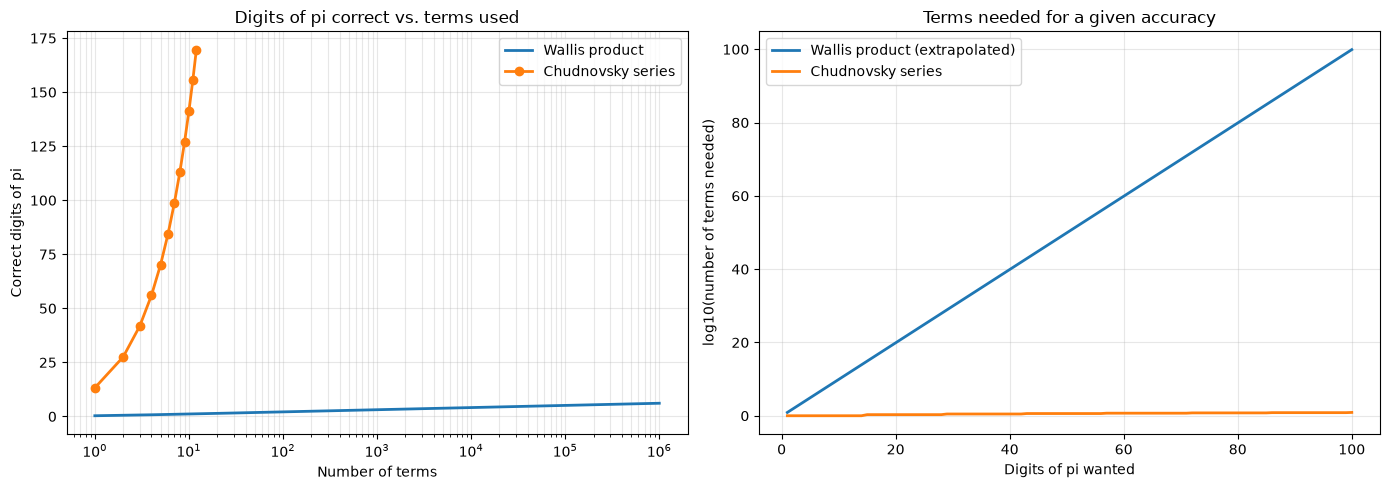

For 100 digits: Wallis needs ~10^100 terms, Chudnovsky needs 8.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import gmpy2
from pi_worker import bs_step

# --- Convergence comparison: Wallis product vs. Chudnovsky series ---
# "Correct digits" = -log10(|approximation - pi|), measured against a high-precision pi.
WALLIS_MAX_TERMS = 10**6
CHUDNOVSKY_MAX_TERMS = 12

with gmpy2.context(precision=1000):
    pi_ref = gmpy2.const_pi()

    # Wallis product: pi/2 = prod_{n>=1} (4n^2) / (4n^2 - 1)
    n = np.arange(1, WALLIS_MAX_TERMS + 1, dtype=np.float64)
    wallis_pi = 2.0 * np.cumprod(4.0 * n**2 / (4.0 * n**2 - 1.0))
    sample = np.unique(np.logspace(0, np.log10(WALLIS_MAX_TERMS), 200).astype(int)) - 1
    wallis_terms = sample + 1
    wallis_digits = -np.log10(np.abs(wallis_pi[sample] - float(pi_ref)))

    # Chudnovsky: pi ~ 426880 * sqrt(10005) * Q / T using the first k terms
    chud_terms = np.arange(1, CHUDNOVSKY_MAX_TERMS + 1)
    chud_digits = []
    for k in chud_terms:
        P, Q, T = bs_step(0, int(k))
        approx = gmpy2.mpfr(Q * 426880) * gmpy2.sqrt(gmpy2.mpfr(10005)) / gmpy2.mpfr(T)
        chud_digits.append(float(-gmpy2.log10(abs(approx - pi_ref))))
    chud_digits = np.array(chud_digits)

# Observed Chudnovsky rate, used to extrapolate "terms needed for D digits"
chud_rate = (chud_digits[-1] - chud_digits[0]) / (chud_terms[-1] - chud_terms[0])
print(f"Wallis:     {wallis_digits[-1]:.1f} correct digits after {WALLIS_MAX_TERMS:,} terms")
print(f"Chudnovsky: {chud_digits[0]:.1f} correct digits after 1 term, {chud_digits[-1]:.1f} after {CHUDNOVSKY_MAX_TERMS} terms"
      f" (~{chud_rate:.2f} digits per term)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: correct digits vs. number of terms
ax1.plot(wallis_terms, wallis_digits, label="Wallis product", linewidth=2)
ax1.plot(chud_terms, chud_digits, "o-", label="Chudnovsky series", linewidth=2)
ax1.set_xscale("log")
ax1.set_xlabel("Number of terms")
ax1.set_ylabel("Correct digits of pi")
ax1.set_title("Digits of pi correct vs. terms used")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend()

# Right: terms needed to reach D digits (Wallis error ~ pi/(4N), so N ~ 10^(D - 0.1))
digits_wanted = np.arange(1, 101)
wallis_needed_log10 = digits_wanted - 0.1
chud_needed = np.ceil(digits_wanted / chud_rate)
ax2.plot(digits_wanted, wallis_needed_log10, label="Wallis product (extrapolated)", linewidth=2)
ax2.plot(digits_wanted, np.log10(chud_needed), label="Chudnovsky series", linewidth=2)
ax2.set_xlabel("Digits of pi wanted")
ax2.set_ylabel("log10(number of terms needed)")
ax2.set_title("Terms needed for a given accuracy")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()
print(f"For 100 digits: Wallis needs ~10^{wallis_needed_log10[-1]:.0f} terms, Chudnovsky needs {int(chud_needed[-1])}.")


## 3. Where does the time go? Time distribution vs. digit scale

Runs `calculate_pi_parallel()` at many sizes and records **checkpoints** for each phase, then plots them:

| Phase | What it is |
|---|---|
| Pool startup + data transfer | Starting the 32 worker processes and sending results back (~0.6 s, roughly constant) |
| Parallel compute | The slowest worker's own binary-splitting time (the critical path) |
| Merge | Combining the 32 partial results in the main process (pairwise **tree merge**) |
| sqrt + divide | Final high-precision `sqrt(10005)` and division |
| Format to string | Converting the result to decimal text |

**Charts:** left = share of total time per phase (stacked bars); right = absolute seconds per phase (stacked area, log-log). The cell also prints which phase dominates at each size.

**What we found (32-core M3 Ultra):**
- Below ~1M digits, process-pool startup dominates; the real work takes milliseconds.
- Above that, the single-core merge dominated. Switching the merge from a left-to-right chain to a balanced tree made it ~3.5x faster (about 2.6x for the whole pipeline at 30M digits).
- The parallel compute phase never dominated. These timings can't prove the run is *memory-bound*; that would need hardware counters (e.g. Instruments).

**Edit `BENCH_SIZES` to change the sizes.** A RAM guard skips sizes estimated to exceed 60% of physical RAM (`FORCE_HUGE = True` overrides). Measured memory was about 130 bytes per digit at 30M digits, so billion-digit runs need hundreds of GB.


Physical RAM: 550 GB
          100 digits: total     0.075s | startup+transfer 0.074 | parallel compute 0.000 | merge 0.000 | sqrt+divide 0.000 | format 0.000
        1,000 digits: total     0.205s | startup+transfer 0.205 | parallel compute 0.000 | merge 0.000 | sqrt+divide 0.000 | format 0.000
       10,000 digits: total     0.290s | startup+transfer 0.289 | parallel compute 0.000 | merge 0.000 | sqrt+divide 0.000 | format 0.000
       50,000 digits: total     0.309s | startup+transfer 0.302 | parallel compute 0.000 | merge 0.004 | sqrt+divide 0.001 | format 0.001
      100,000 digits: total     0.321s | startup+transfer 0.302 | parallel compute 0.001 | merge 0.014 | sqrt+divide 0.003 | format 0.002
      200,000 digits: total     0.352s | startup+transfer 0.300 | parallel compute 0.001 | merge 0.038 | sqrt+divide 0.006 | format 0.006
      500,000 digits: total     0.480s | startup+transfer 0.306 | parallel compute 0.003 | merge 0.135 | sqrt+divide 0.017 | format 0.019
    1,000,000

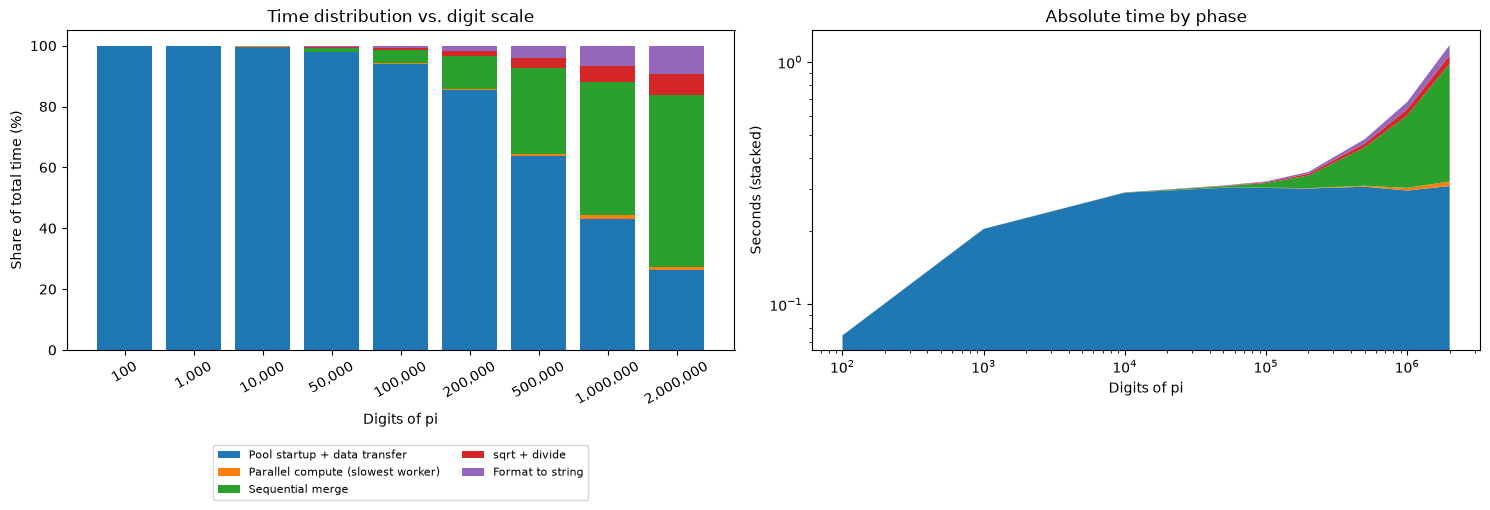

          100: dominant phase = Pool startup + data transfer
        1,000: dominant phase = Pool startup + data transfer
       10,000: dominant phase = Pool startup + data transfer
       50,000: dominant phase = Pool startup + data transfer
      100,000: dominant phase = Pool startup + data transfer
      200,000: dominant phase = Pool startup + data transfer
      500,000: dominant phase = Pool startup + data transfer
    1,000,000: dominant phase = Sequential merge
    2,000,000: dominant phase = Sequential merge

➡️ Dominant phase changes between 500,000 and 1,000,000 digits: Pool startup + data transfer -> Sequential merge


In [6]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from pi_worker import calculate_pi_parallel

# --- Time distribution vs. digit scale ---
# calculate_pi_parallel() records checkpoints into a `timings` dict. We run it at increasing
# digit counts and stack the phases to see which one dominates at each scale.
BENCH_SIZES = [100, 1_000, 10_000, 50_000, 100_000, 200_000, 500_000,
               1_000_000, 2_000_000]
BENCH_REPEATS_SMALL = 3   # best-of-N for sizes up to 1M digits (timings are noisy when tiny)

# Safety guard for the huge sizes. Measured here: ~130 bytes of RAM per digit at 30M digits
# (main process + 32 workers), growing slightly faster than linearly, so use a conservative 200.
PHYS_RAM = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
BYTES_PER_DIGIT = 200
MAX_RAM_FRACTION = 0.6    # skip a size if its estimated RAM exceeds this share of physical RAM
FORCE_HUGE = False        # set True to run every size regardless of the estimate

def run_once(digits):
    t = {}
    pi = calculate_pi_parallel(digits, timings=t, verbose=False)
    t0 = time.perf_counter()
    _ = f"{pi:.{digits}f}"            # checkpoint: convert to a decimal string
    t["format"] = time.perf_counter() - t0
    t["total"] = t["setup"] + t["pool_wall"] + t["merge"] + t["divide"] + t["format"]
    return t

print(f"Physical RAM: {PHYS_RAM / 1e9:,.0f} GB")
runs = {}
for d in BENCH_SIZES:
    est_ram = d * BYTES_PER_DIGIT
    if est_ram > MAX_RAM_FRACTION * PHYS_RAM and not FORCE_HUGE:
        print(f"{d:>13,} digits: SKIPPED (estimated ~{est_ram / 1e9:,.0f} GB RAM, "
              f"over {MAX_RAM_FRACTION:.0%} of physical RAM; set FORCE_HUGE = True to run anyway)")
        continue
    if d >= 100_000_000:
        # Rough extrapolation from timings measured at 30M digits (~25 s, slightly super-linear)
        est_minutes = 25.4 * (d / 3e7) ** 1.15 / 60
        print(f"{d:>13,} digits: starting; expect ~{est_minutes:,.0f} min and up to ~{est_ram / 1e9:,.0f} GB RAM...")
    repeats = BENCH_REPEATS_SMALL if d <= 1_000_000 else 1
    best = min((run_once(d) for _ in range(repeats)), key=lambda r: r["total"])
    runs[d] = best
    print(f"{d:>13,} digits: total {best['total']:9.3f}s | startup+transfer {best['pool_overhead']:.3f} "
          f"| parallel compute {best['worker_max']:.3f} | merge {best['merge']:.3f} "
          f"| sqrt+divide {best['divide']:.3f} | format {best['format']:.3f}")

phases = [
    ("Pool startup + data transfer", "pool_overhead"),
    ("Parallel compute (slowest worker)", "worker_max"),
    ("Sequential merge", "merge"),
    ("sqrt + divide", "divide"),
    ("Format to string", "format"),
]
sizes = list(runs)
# Setup time is tiny; fold it into the startup bucket
values = np.array([[runs[d][key] + (runs[d]["setup"] if key == "pool_overhead" else 0.0)
                    for d in sizes] for _, key in phases])
shares = 100 * values / values.sum(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: share of total time per phase (stacked bars)
x = np.arange(len(sizes))
bottom = np.zeros(len(sizes))
for (label, _), row in zip(phases, shares):
    ax1.bar(x, row, bottom=bottom, label=label)
    bottom += row
ax1.set_xticks(x)
ax1.set_xticklabels([f"{d:,}" for d in sizes], rotation=30)
ax1.set_xlabel("Digits of pi")
ax1.set_ylabel("Share of total time (%)")
ax1.set_title("Time distribution vs. digit scale")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=8)

# Right: absolute seconds per phase (stacked area, log-log)
ax2.stackplot(sizes, values, labels=[p[0] for p in phases])
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Digits of pi")
ax2.set_ylabel("Seconds (stacked)")
ax2.set_title("Absolute time by phase")

plt.tight_layout()
plt.show()

# Which phase dominates at each scale, and where it changes
names = [p[0] for p in phases]
dominant = [names[int(np.argmax(col))] for col in values.T]
for d, name in zip(sizes, dominant):
    print(f"{d:>13,}: dominant phase = {name}")
for i in range(1, len(sizes)):
    if dominant[i] != dominant[i - 1]:
        print(f"\n➡️ Dominant phase changes between {sizes[i-1]:,} and {sizes[i]:,} digits: "
              f"{dominant[i-1]} -> {dominant[i]}")
